In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q osmnx geopandas pyyaml

import os, sys, shutil, importlib
import geopandas as gpd
import pandas as pd

base = "/content/drive/MyDrive/env-exposure-linkage"
os.chdir(base)
for folder in ["config", "src", "docs", "outputs"]:
    os.makedirs(f"{base}/{folder}", exist_ok=True)

shutil.copy(f"{base}/data/processed/homes.gpkg", "/content/homes.gpkg")
homes = gpd.read_file("/content/homes.gpkg")
print("Loaded", len(homes), "homes | CRS:", homes.crs.to_epsg())

Mounted at /content/drive
Loaded 500 homes | CRS: 25832


In [2]:
%%writefile /content/drive/MyDrive/env-exposure-linkage/config/exposures.yaml
crs: 25832   # ETRS89 / UTM zone 32N, metres

exposures:
  - name: green_share
    description: Share of buffer area covered by green space (parks, forest, grass, meadows)
    method: area_share
    source_file: data/raw/osm_green.gpkg
    source: OpenStreetMap (accessed October 2026)
    buffers_m: [100, 300, 500]
    unit: proportion (0-1)
    valid_range: [0, 1]

  - name: dist_green_m
    description: Distance from home to the nearest green space
    method: distance
    source_file: data/raw/osm_green.gpkg
    source: OpenStreetMap (accessed October 2026)
    unit: metres
    valid_range: [0, 5000]

  - name: dist_blue_m
    description: Distance from home to the nearest water body or river
    method: distance
    source_file: data/raw/osm_blue.gpkg
    source: OpenStreetMap (accessed October 2026)
    unit: metres
    valid_range: [0, 5000]

Writing /content/drive/MyDrive/env-exposure-linkage/config/exposures.yaml


In [3]:
%%writefile /content/drive/MyDrive/env-exposure-linkage/src/exposures.py
"""Link environmental exposures to residential locations, driven by config/exposures.yaml."""
import shutil
import geopandas as gpd
import pandas as pd
import yaml
from shapely.ops import unary_union


def load_layer(path, crs):
    """Copy a GeoPackage from Drive to local disk, read it, reproject and repair geometries."""
    local = "/content/_layer.gpkg"
    shutil.copy(path, local)
    gdf = gpd.read_file(local).to_crs(crs)
    gdf["geometry"] = gdf.geometry.make_valid()
    return gdf


def merged_polygons(layer, simplify_m=1):
    """Merge overlapping features and keep clean polygons only (avoids double counting)."""
    merged = unary_union(layer.geometry.values)
    parts = gpd.GeoDataFrame(geometry=[merged], crs=layer.crs).explode(index_parts=False)
    parts = parts[parts.geom_type.isin(["Polygon", "MultiPolygon"])]
    parts["geometry"] = parts.geometry.simplify(simplify_m)
    return parts[~parts.is_empty & parts.is_valid].reset_index(drop=True)


def area_share(homes, layer, buffers_m):
    """Share of each circular buffer covered by the layer's polygons."""
    parts = merged_polygons(layer)
    results = {}
    for b in buffers_m:
        buf = gpd.GeoDataFrame({"home_id": homes["home_id"]}, geometry=homes.buffer(b), crs=homes.crs)
        overlap = gpd.overlay(buf, parts, how="intersection")
        covered = overlap.assign(a=overlap.area).groupby("home_id")["a"].sum()
        results[b] = (homes["home_id"].map(covered).fillna(0) / buf.area.values).round(3).values
    return results


def distance(homes, layer):
    """Distance from each home to the nearest feature of the layer (0 if inside)."""
    merged = unary_union(layer.geometry.values)
    return homes.distance(merged).round(1).values


def run_pipeline(config_path, homes, base_dir="."):
    """Compute all exposures listed in the config. Returns the exposure table and a data dictionary."""
    with open(config_path) as f:
        cfg = yaml.safe_load(f)
    homes = homes.to_crs(cfg["crs"])
    table = homes[["home_id"]].copy()
    dictionary = []

    for ex in cfg["exposures"]:
        layer = load_layer(f"{base_dir}/{ex['source_file']}", cfg["crs"])
        entry = {
            "description": ex["description"], "method": ex["method"], "unit": ex["unit"],
            "source": ex["source"], "source_file": ex["source_file"],
            "valid_min": ex["valid_range"][0], "valid_max": ex["valid_range"][1],
        }
        if ex["method"] == "area_share":
            for b, values in area_share(homes, layer, ex["buffers_m"]).items():
                col = f"{ex['name']}_{b}m"
                table[col] = values
                dictionary.append({"variable": col, "buffer_m": b, **entry})
        elif ex["method"] == "distance":
            table[ex["name"]] = distance(homes, layer)
            dictionary.append({"variable": ex["name"], "buffer_m": None, **entry})
        else:
            raise ValueError(f"Unknown method: {ex['method']}")
        print(f"Done: {ex['name']}")

    return table, pd.DataFrame(dictionary)

Writing /content/drive/MyDrive/env-exposure-linkage/src/exposures.py


In [4]:
sys.path.insert(0, f"{base}/src")
import exposures
importlib.reload(exposures)

table, dictionary = exposures.run_pipeline(f"{base}/config/exposures.yaml", homes, base_dir=base)

table.to_csv(f"{base}/data/processed/homes_exposures.csv", index=False)
dictionary.to_csv(f"{base}/docs/data_dictionary.csv", index=False)

print("\nVariables:", len(dictionary))
dictionary[["variable", "description", "unit", "source"]]

Done: green_share
Done: dist_green_m
Done: dist_blue_m

Variables: 5


,variable,description,unit,source
0,green_share_100m,Share of buffer area covered by green space (p...,proportion (0-1),OpenStreetMap (accessed October 2026)
1,green_share_300m,Share of buffer area covered by green space (p...,proportion (0-1),OpenStreetMap (accessed October 2026)
2,green_share_500m,Share of buffer area covered by green space (p...,proportion (0-1),OpenStreetMap (accessed October 2026)
3,dist_green_m,Distance from home to the nearest green space,metres,OpenStreetMap (accessed October 2026)
4,dist_blue_m,Distance from home to the nearest water body o...,metres,OpenStreetMap (accessed October 2026)


In [5]:
checks = []
for _, row in dictionary.iterrows():
    col = table[row["variable"]]
    checks.append({
        "variable": row["variable"],
        "n": len(col),
        "missing": int(col.isna().sum()),
        "min": round(col.min(), 3),
        "mean": round(col.mean(), 3),
        "max": round(col.max(), 3),
        "out_of_range": int(((col < row["valid_min"]) | (col > row["valid_max"])).sum()),
    })
qc = pd.DataFrame(checks)
qc.to_csv(f"{base}/docs/quality_report.csv", index=False)

print("Duplicate home IDs:", int(table["home_id"].duplicated().sum()))
print("Coordinate system: EPSG", homes.crs.to_epsg())
print("All checks passed" if qc[["missing", "out_of_range"]].sum().sum() == 0 else "Check the flagged variables below")
qc

Duplicate home IDs: 0
Coordinate system: EPSG 25832
All checks passed


,variable,n,missing,min,mean,max,out_of_range
0,green_share_100m,500,0,0.000,0.078,0.670,0
1,green_share_300m,500,0,0.000,0.127,0.657,0
2,green_share_500m,500,0,0.006,0.153,0.636,0
3,dist_green_m,500,0,0.000,86.770,348.700,0
4,dist_blue_m,500,0,1.000,359.027,1208.300,0


In [6]:
%%writefile -a /content/drive/MyDrive/env-exposure-linkage/config/exposures.yaml

  - name: blue_share
    description: Share of buffer area covered by water bodies
    method: area_share
    source_file: data/raw/osm_blue.gpkg
    source: OpenStreetMap (accessed October 2026)
    buffers_m: [300, 500]
    unit: proportion (0-1)
    valid_range: [0, 1]

Appending to /content/drive/MyDrive/env-exposure-linkage/config/exposures.yaml


In [7]:
importlib.reload(exposures)
table, dictionary = exposures.run_pipeline(f"{base}/config/exposures.yaml", homes, base_dir=base)
table.to_csv(f"{base}/data/processed/homes_exposures.csv", index=False)
dictionary.to_csv(f"{base}/docs/data_dictionary.csv", index=False)
print("\nVariables:", len(dictionary))
dictionary[["variable", "description", "unit", "source"]]

Done: green_share
Done: dist_green_m
Done: dist_blue_m
Done: blue_share

Variables: 7


,variable,description,unit,source
0,green_share_100m,Share of buffer area covered by green space (p...,proportion (0-1),OpenStreetMap (accessed October 2026)
1,green_share_300m,Share of buffer area covered by green space (p...,proportion (0-1),OpenStreetMap (accessed October 2026)
2,green_share_500m,Share of buffer area covered by green space (p...,proportion (0-1),OpenStreetMap (accessed October 2026)
3,dist_green_m,Distance from home to the nearest green space,metres,OpenStreetMap (accessed October 2026)
4,dist_blue_m,Distance from home to the nearest water body o...,metres,OpenStreetMap (accessed October 2026)
5,blue_share_300m,Share of buffer area covered by water bodies,proportion (0-1),OpenStreetMap (accessed October 2026)
6,blue_share_500m,Share of buffer area covered by water bodies,proportion (0-1),OpenStreetMap (accessed October 2026)


In [8]:
checks = []
for _, row in dictionary.iterrows():
    col = table[row["variable"]]
    checks.append({
        "variable": row["variable"], "n": len(col),
        "missing": int(col.isna().sum()),
        "min": round(col.min(), 3), "mean": round(col.mean(), 3), "max": round(col.max(), 3),
        "out_of_range": int(((col < row["valid_min"]) | (col > row["valid_max"])).sum()),
    })
qc = pd.DataFrame(checks)
qc.to_csv(f"{base}/docs/quality_report.csv", index=False)
print("All checks passed" if qc[["missing", "out_of_range"]].sum().sum() == 0 else "Check the flagged variables below")
qc

All checks passed


,variable,n,missing,min,mean,max,out_of_range
0,green_share_100m,500,0,0.000,0.078,0.670,0
1,green_share_300m,500,0,0.000,0.127,0.657,0
2,green_share_500m,500,0,0.006,0.153,0.636,0
3,dist_green_m,500,0,0.000,86.770,348.700,0
4,dist_blue_m,500,0,1.000,359.027,1208.300,0
5,blue_share_300m,500,0,0.000,0.013,0.290,0
6,blue_share_500m,500,0,0.000,0.020,0.338,0


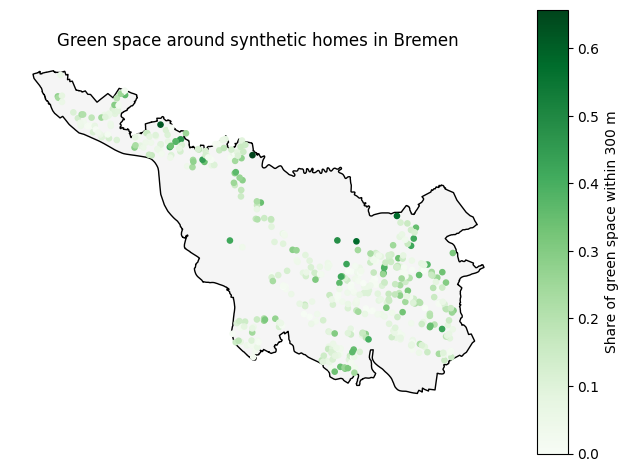

In [9]:
import matplotlib.pyplot as plt
shutil.copy(f"{base}/data/processed/bremen_boundary.gpkg", "/content/city.gpkg")
city = gpd.read_file("/content/city.gpkg")
plot = homes.merge(table, on="home_id")

fig, ax = plt.subplots(figsize=(8, 8))
city.plot(ax=ax, facecolor="whitesmoke", edgecolor="black")
plot.plot(ax=ax, column="green_share_300m", cmap="Greens", markersize=14, legend=True,
          legend_kwds={"label": "Share of green space within 300 m"})
ax.set_title("Green space around synthetic homes in Bremen")
ax.set_axis_off()
plt.savefig(f"{base}/outputs/map_green_share_300m.png", dpi=200, bbox_inches="tight")
plt.show()

Mounted at /content/drive
